<a href="https://colab.research.google.com/github/rahulmenons/Django-polls-app/blob/main/MAAI901_CLIP_Waterbirds_Executed_Reviewed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAAI901 · Background Bias in CLIP

**Study:** A comparison of zero-shot CLIP, standard linear probing, and group-balanced linear probing on Waterbirds.

**Research question:** Does group-balanced training improve worst-group accuracy for images where the bird category and scene background are mismatched?

**Important:** This notebook is an *executable research protocol*, not a completed experiment. Do not report any test values until you run the cells. The pretrained CLIP image encoder is **frozen**; the two linear probes train only a logistic-regression head. This is **embedding extraction**, explicitly permitted by the MAAI901 brief, **not ViT fine-tuning**.

**Evaluation protocol**: Use the official train/validation/test splits. Choose each linear probe's regularization strength on the validation set based on worst-group accuracy, with overall accuracy as a tie-breaker. Do not select hyperparameters using test results.

**Sources:** [Original Waterbirds authors](https://github.com/ssagawa/overparam_spur_corr) · [Dataset mirror](https://huggingface.co/datasets/grodino/waterbirds) · [Official CLIP implementation](https://github.com/openai/CLIP) · [CLIP paper](https://proceedings.mlr.press/v139/radford21a.html) · [Last-layer retraining paper](https://mlanthology.org/iclr/2023/kirichenko2023iclr-last/)

## 0 · Setup

For **Google Colab**, first select **Runtime → Change runtime type → GPU** (if available) and run all cells sequentially. Initial runs download approximately 0.5 GB of dataset content plus CLIP weights. CPU also works but is slower. Package versions and device will be logged for reproducibility.

In [1]:
%pip -q install "datasets>=3.0" "scikit-learn>=1.3" pandas matplotlib seaborn tqdm ftfy regex
%pip -q install git+https://github.com/openai/CLIP.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os, json, random, warnings, platform, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from PIL import Image
from datasets import load_dataset
import torch, clip
from torch.utils.data import Dataset, DataLoader
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import sklearn

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
BATCH_SIZE = 64 if DEVICE == 'cuda' else 16
OUT = Path('maai901_outputs'); OUT.mkdir(exist_ok=True)
print('Device:', DEVICE, '| Python:', sys.version.split()[0], '| PyTorch:', torch.__version__, '| sklearn:', sklearn.__version__)
print('Seed:', SEED, '| Batch size:', BATCH_SIZE)

Device: cuda | Python: 3.13.16 | PyTorch: 2.11.0+cu130 | sklearn: 1.6.1
Seed: 42 | Batch size: 64


## 1 · Dataset audit and pre-processing justification

Waterbirds combines bird photos from CUB with background scenes from Places. The dataset's **label** indicates landbird (0) or waterbird (1), while **place** indicates land (0) or water (1). Hence groups are `(label, place)` with four combinations. Natural bird images from this dataset are *synthetically composited*. That is a central ecological-validity limitation.

**Pre-processing choice:** Convert images to RGB and apply CLIP's prescribed resize/crop, tensor conversion and normalization. Avoid extra augmentation in this controlled, fixed-encoder study; cropping can still remove bird features, which should be mentioned as a limitation.

In [3]:
ds = load_dataset('grodino/waterbirds')
expected = {'train': 4795, 'validation': 1199, 'test': 5794}
assert set(expected).issubset(ds.keys()), f'Unexpected split names: {list(ds)}'
for split, n in expected.items():
    assert len(ds[split]) == n, f'{split}: expected {n}, got {len(ds[split])}'
    assert {'image', 'label', 'place'}.issubset(ds[split].column_names)
print(ds)
print('Class labels:', ds['train'].features['label'])
print('Background labels:', ds['train'].features['place'])

README.md:   0%|          | 0.00/10.7k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  212MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 48.1MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/4795 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1199 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5794 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label', 'place', 'bird'],
        num_rows: 4795
    })
    validation: Dataset({
        features: ['image', 'label', 'place', 'bird'],
        num_rows: 1199
    })
    test: Dataset({
        features: ['image', 'label', 'place', 'bird'],
        num_rows: 5794
    })
})
Class labels: ClassLabel(names=['landbird', 'waterbird'])
Background labels: ClassLabel(names=['land', 'water'])


split              test  train  validation
group                                     
Landbird / Land    2255   3498         467
Landbird / Water   2255    184         466
Waterbird / Land    642     56         133
Waterbird / Water   642   1057         133


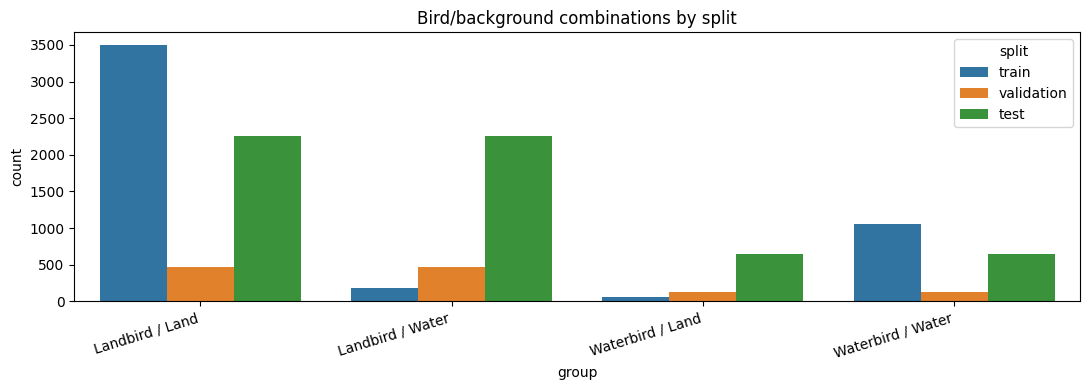

In [4]:
CLASS_NAMES = {0: 'landbird', 1: 'waterbird'}
PLACE_NAMES = {0: 'land background', 1: 'water background'}
GROUP_NAMES = {0: 'Landbird / Land', 1: 'Landbird / Water',
               2: 'Waterbird / Land', 3: 'Waterbird / Water'}

def get_metadata(data_split):
    y = np.asarray(data_split['label'], dtype=int)
    p = np.asarray(data_split['place'], dtype=int)
    return pd.DataFrame({'label': y, 'place': p, 'group': 2*y + p})

rows = []
for split in ('train', 'validation', 'test'):
    m = get_metadata(ds[split])
    for group in range(4):
        rows.append({'split': split, 'group': GROUP_NAMES[group],
                     'count': int((m['group'] == group).sum())})
counts = pd.DataFrame(rows)
print(counts.pivot(index='group', columns='split', values='count'))
counts.to_csv(OUT / 'group_counts.csv', index=False)
plt.figure(figsize=(11, 4))
sns.barplot(data=counts, x='group', y='count', hue='split')
plt.xticks(rotation=17, ha='right'); plt.title('Bird/background combinations by split')
plt.tight_layout(); plt.savefig(OUT / 'fig_01_group_counts.png', dpi=170); plt.show()

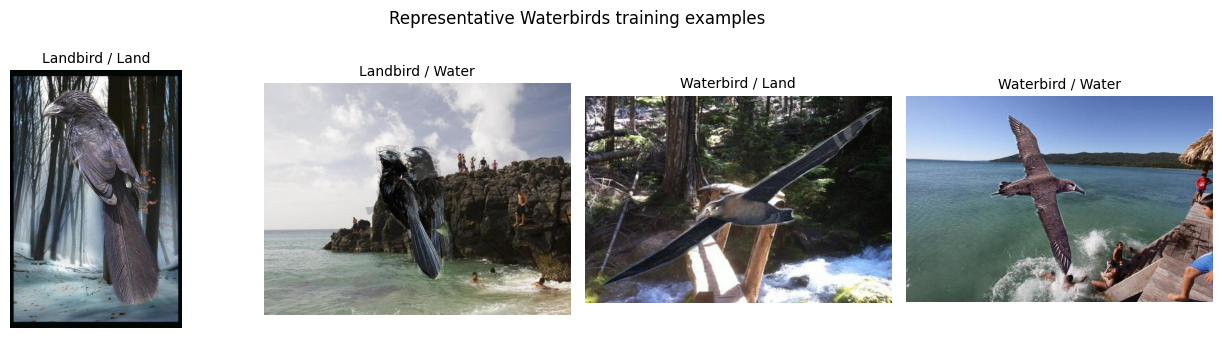

In [5]:
# Show one training image from each group; class and background labels come from metadata.
train_meta = get_metadata(ds['train'])
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for group, ax in enumerate(axes):
    idx = int(np.flatnonzero(train_meta.group.to_numpy() == group)[0])
    ax.imshow(ds['train'][idx]['image'].convert('RGB'))
    ax.set_title(GROUP_NAMES[group], fontsize=10); ax.axis('off')
plt.suptitle('Representative Waterbirds training examples')
plt.tight_layout(); plt.savefig(OUT / 'fig_02_dataset_examples.png', dpi=170); plt.show()

## 2 · Load pretrained CLIP ViT-B/32 and extract embeddings

No CLIP backbone weights are updated. Feature extraction is performed once for each official split and cached locally. The CLIP preprocessing pipeline is used without modification.

In [6]:
model, preprocess = clip.load('ViT-B/32', device=DEVICE, jit=False)
model.eval()
print('CLIP model: ViT-B/32')
print('CLIP image preprocessing:', preprocess)

class ImageOnlyDataset(Dataset):
    def __init__(self, hf_split, transform):
        self.data = hf_split
        self.transform = transform
    def __len__(self): return len(self.data)
    def __getitem__(self, idx):
        image = self.data[idx]['image'].convert('RGB')
        return self.transform(image)

@torch.inference_mode()
def get_clip_features(split):
    cache_path = OUT / f'clip_vitb32_{split}_features.npz'
    y = np.asarray(ds[split]['label'], dtype=np.int64)
    p = np.asarray(ds[split]['place'], dtype=np.int64)
    if cache_path.exists():
        cache = np.load(cache_path)
        if np.array_equal(cache['y'], y) and np.array_equal(cache['place'], p):
            print('Loaded cached features:', cache_path)
            return cache['X'].astype(np.float32), y, p
        print('Ignoring stale feature cache:', cache_path)
    loader = DataLoader(ImageOnlyDataset(ds[split], preprocess), batch_size=BATCH_SIZE,
                        shuffle=False, num_workers=0, pin_memory=(DEVICE=='cuda'))
    features = []
    for batch in tqdm(loader, desc=f'Extracting {split}'):
        z = model.encode_image(batch.to(DEVICE)).float()
        z = z / z.norm(dim=-1, keepdim=True).clamp(min=1e-8)
        features.append(z.cpu().numpy())
    X = np.concatenate(features).astype(np.float32)
    assert X.shape[0] == len(ds[split])
    np.savez_compressed(cache_path, X=X, y=y, place=p)
    return X, y, p

X_train, y_train, p_train = get_clip_features('train')
X_val, y_val, p_val = get_clip_features('validation')
X_test, y_test, p_test = get_clip_features('test')
print('Embedding dimensions:', X_train.shape, X_val.shape, X_test.shape)

100%|███████████████████████████████████████| 338M/338M [00:12<00:00, 28.1MiB/s]


CLIP model: ViT-B/32
CLIP image preprocessing: Compose(
    Resize(size=224, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    <function _convert_image_to_rgb at 0x7b1679d859e0>
    ToTensor()
    Normalize(mean=(0.48145466, 0.4578275, 0.40821073), std=(0.26862954, 0.26130258, 0.27577711))
)


Extracting train:   0%|          | 0/75 [00:00<?, ?it/s]

Extracting validation:   0%|          | 0/19 [00:00<?, ?it/s]

Extracting test:   0%|          | 0/91 [00:00<?, ?it/s]

Embedding dimensions: (4795, 512) (1199, 512) (5794, 512)


## 3 · Define evaluation metrics

**Accuracy** and **macro F1** summarize overall performance. The main robustness endpoint is **worst-group accuracy**: the lowest accuracy among the four class–background groups. A smaller **background-alignment gap** (aligned-group accuracy minus mismatched-group accuracy) may indicate reduced reliance on background cues, but it does **not** prove causality or perfect background invariance.

In [7]:
def metrics_for(y, place, predictions):
    y = np.asarray(y); place = np.asarray(place); predictions = np.asarray(predictions)
    groups = 2*y + place
    accs = {GROUP_NAMES[g]: float(np.mean(predictions[groups == g] == y[groups == g]))
            for g in range(4) if np.any(groups == g)}
    aligned = (y == place)
    results = {
        'accuracy': float(accuracy_score(y, predictions)),
        'macro_f1': float(f1_score(y, predictions, average='macro', zero_division=0)),
        'worst_group_accuracy': float(min(accs.values())),
        'mean_group_accuracy': float(np.mean(list(accs.values()))),
        'alignment_gap': float(np.mean(predictions[aligned] == y[aligned]) -
                               np.mean(predictions[~aligned] == y[~aligned])),
        'by_group': accs
    }
    return results

def print_metrics(name, vals):
    print(f'{name}: accuracy={vals["accuracy"]:.2%} | macro-F1={vals["macro_f1"]:.3f} | '
          f'worst group={vals["worst_group_accuracy"]:.2%} | alignment gap={vals["alignment_gap"]:.2%}')
    for group, acc in vals['by_group'].items(): print(f'  {group}: {acc:.2%}')

## 4 · Experiment A: zero-shot CLIP

Text prompts are set **before evaluating the test set**. CLIP computes visual/text similarity. Here prompts are deliberately simple to match the two class descriptions; possible prompt sensitivity is a limitation and can be explored later using validation data only.

In [8]:
PROMPTS = ['a photo of a land bird', 'a photo of a water bird']
with torch.inference_mode():
    tokens = clip.tokenize(PROMPTS).to(DEVICE)
    text_embeddings = model.encode_text(tokens).float()
    text_embeddings = text_embeddings / text_embeddings.norm(dim=-1, keepdim=True)
text_embeddings = text_embeddings.cpu().numpy()

def zero_shot_predict(X):
    # Normalizing image/text features makes dot products cosine similarities.
    return (X @ text_embeddings.T).argmax(axis=1)

zero_val = zero_shot_predict(X_val)
print_metrics('Zero-shot / validation', metrics_for(y_val, p_val, zero_val))

Zero-shot / validation: accuracy=71.89% | macro-F1=0.637 | worst group=27.07% | alignment gap=42.25%
  Landbird / Land: 95.93%
  Landbird / Water: 57.51%
  Waterbird / Land: 27.07%
  Waterbird / Water: 82.71%


## 5 · Experiments B & C: linear probes on frozen CLIP embeddings

- **B: Standard linear probe** fits logistic regression on all training embeddings without group reweighting.
- **C: Group-balanced linear probe** uses inverse-frequency weights by `(bird label, background)` group, so each group contributes the same total weight to the objective. This method *requires training-time group labels*, a deployment limitation worth emphasizing.

Both approaches use the **same frozen embeddings, same hyperparameter candidate values, same official splits**, and select regularization `C` using validation **worst-group accuracy**. This isolates the effect of group weighting. No test labels are used for selection.

In [9]:
C_OPTIONS = [0.01, 0.1, 1.0, 10.0]
train_group = 2*y_train + p_train
sizes = np.bincount(train_group, minlength=4)
assert np.all(sizes > 0), 'Expected all 4 groups in the training data'
# Normalize such that mean training weight = 1, with equal TOTAL weights for each group.
group_weights = len(y_train) / (4.0 * sizes[train_group])
print('Training counts per group:', dict(zip([GROUP_NAMES[i] for i in range(4)], sizes.tolist())))
print('Mean sample weight:', round(group_weights.mean(), 5))

def select_probe(name, weights=None):
    trials = []
    models = {}
    for c in C_OPTIONS:
        clf = LogisticRegression(C=c, max_iter=2500, solver='lbfgs', random_state=SEED)
        clf.fit(X_train, y_train, sample_weight=weights)
        pred = clf.predict(X_val)
        m = metrics_for(y_val, p_val, pred)
        trials.append({'method': name, 'C': c, 'val_worst_group': m['worst_group_accuracy'],
                       'val_accuracy': m['accuracy'], 'val_macro_f1': m['macro_f1']})
        models[c] = clf
    trials_df = pd.DataFrame(trials)
    winner = trials_df.sort_values(['val_worst_group', 'val_accuracy', 'C'],
                                   ascending=[False, False, True]).iloc[0]
    best_c = float(winner['C'])
    print(f'{name}: chosen C={best_c}, validation worst-group={winner["val_worst_group"]:.2%}')
    return models[best_c], trials_df

standard_clf, trials_standard = select_probe('Standard linear probe')
balanced_clf, trials_balanced = select_probe('Group-balanced linear probe', group_weights)
trials_df = pd.concat([trials_standard, trials_balanced], ignore_index=True)
trials_df.to_csv(OUT / 'validation_hyperparameter_trials.csv', index=False)
display(trials_df)

Training counts per group: {'Landbird / Land': 3498, 'Landbird / Water': 184, 'Waterbird / Land': 56, 'Waterbird / Water': 1057}
Mean sample weight: 1.0
Standard linear probe: chosen C=10.0, validation worst-group=46.62%
Group-balanced linear probe: chosen C=1.0, validation worst-group=80.45%


,method,C,val_worst_group,val_accuracy,val_macro_f1
0,Standard linear probe,0.01,0.000000,0.778148,0.437617
1,Standard linear probe,0.10,0.045113,0.773978,0.661086
2,Standard linear probe,1.00,0.285714,0.773978,0.697796
3,Standard linear probe,10.00,0.466165,0.808173,0.745500
4,Group-balanced linear probe,0.01,0.751073,0.839033,0.796135
5,Group-balanced linear probe,0.10,0.781955,0.863219,0.821623
6,Group-balanced linear probe,1.00,0.804511,0.887406,0.849117
7,Group-balanced linear probe,10.00,0.796992,0.884070,0.844646


## 6 · Final, one-time held-out test evaluation

We now apply the **already selected** classifiers to the held-out test set. If an approach performs poorly, report it as-is and discuss plausible causes rather than tuning on the test set.
**Checkpoint:** Confirm that both validation tuning tables exist and that neither selected classifier was chosen using the test labels. Refrain from rerunning the modeling stages in response to test performance; report the original results.


In [10]:
predictions = {
    'Zero-shot CLIP': zero_shot_predict(X_test),
    'Standard linear probe': standard_clf.predict(X_test),
    'Group-balanced linear probe': balanced_clf.predict(X_test),
}
all_metrics = {method: metrics_for(y_test, p_test, pred) for method, pred in predictions.items()}
summary = pd.DataFrame([{
    'method': name,
    **{k: v for k, v in vals.items() if k != 'by_group'}
} for name, vals in all_metrics.items()])
print('HELD-OUT TEST RESULTS (report only real output from this cell):')
display(summary.style.format({col: '{:.2%}' for col in ['accuracy','worst_group_accuracy','mean_group_accuracy','alignment_gap']}
                             | {'macro_f1': '{:.3f}'}))
summary.to_csv(OUT / 'test_results_summary.csv', index=False)
with open(OUT / 'test_results_full.json', 'w') as f:
    json.dump(all_metrics, f, indent=2)

HELD-OUT TEST RESULTS (report only real output from this cell):


,method,accuracy,macro_f1,worst_group_accuracy,mean_group_accuracy,alignment_gap
0,Zero-shot CLIP,71.04%,0.625,23.83%,64.52%,43.29%
1,Standard linear probe,79.41%,0.729,43.46%,75.60%,37.73%
2,Group-balanced linear probe,87.59%,0.836,82.24%,87.32%,10.11%


### Optional statistical uncertainty: stratified paired bootstrap

Worst-group accuracy is calculated from four subgroups with finite sample sizes. To avoid overinterpreting small differences, this cell estimates a **95% percentile bootstrap interval** for each method's worst-group accuracy and for the **paired difference (balanced − standard)**. We resample test examples *within each subgroup*, preserving subgroup sizes, and use the **same sampled indices across the two methods**. These are descriptive uncertainty intervals conditional on this dataset and fixed trained models, **not** evidence of generalization across datasets or training seeds. No model selection occurs here.


In [11]:
# Exploratory uncertainty analysis; evaluate only after the protocol is finalized.
N_BOOTSTRAPS = 600
rng = np.random.default_rng(SEED + 123)
test_groups = 2*y_test + p_test
indices_by_group = [np.flatnonzero(test_groups == g) for g in range(4)]
assert all(len(idx) > 0 for idx in indices_by_group), 'Unexpected empty test group'
method_names = list(predictions)
correct = {name: (np.asarray(predictions[name]) == y_test).astype(np.float64)
           for name in method_names}
boot_wga = {name: np.empty(N_BOOTSTRAPS, dtype=np.float64) for name in method_names}
for iteration in range(N_BOOTSTRAPS):
    # Resample *the same* test indices for every method (paired design).
    sampled = [rng.choice(idx, size=len(idx), replace=True) for idx in indices_by_group]
    for name in method_names:
        boot_wga[name][iteration] = min(correct[name][idx].mean() for idx in sampled)
ci_rows = []
for name in method_names:
    low, high = np.quantile(boot_wga[name], [0.025, 0.975])
    ci_rows.append({'method': name, 'worst_group_accuracy': all_metrics[name]['worst_group_accuracy'],
                    'ci_95_low': float(low), 'ci_95_high': float(high)})
ci_df = pd.DataFrame(ci_rows)
ci_df.to_csv(OUT / 'test_worst_group_bootstrap_ci.csv', index=False)
paired_difference = boot_wga['Group-balanced linear probe'] - boot_wga['Standard linear probe']
point_diff = (all_metrics['Group-balanced linear probe']['worst_group_accuracy'] -
              all_metrics['Standard linear probe']['worst_group_accuracy'])
diff_low, diff_high = np.quantile(paired_difference, [0.025, 0.975])
print('95% bootstrap percentile intervals for test worst-group accuracy:')
display(ci_df.style.format({'worst_group_accuracy':'{:.2%}', 'ci_95_low':'{:.2%}', 'ci_95_high':'{:.2%}'}))
print(f'Balanced − standard worst-group accuracy: {point_diff:+.2%} '
      f'(paired bootstrap 95% interval {diff_low:+.2%} to {diff_high:+.2%}).')
pd.DataFrame([{'difference_worst_group_accuracy': float(point_diff),
               'ci_95_low': float(diff_low), 'ci_95_high': float(diff_high),
               'bootstrap_resamples': N_BOOTSTRAPS}]).to_csv(
    OUT / 'test_paired_worst_group_difference_ci.csv', index=False)


95% bootstrap percentile intervals for test worst-group accuracy:


,method,worst_group_accuracy,ci_95_low,ci_95_high
0,Zero-shot CLIP,23.83%,20.56%,27.26%
1,Standard linear probe,43.46%,39.56%,47.04%
2,Group-balanced linear probe,82.24%,79.12%,83.46%


Balanced − standard worst-group accuracy: +38.79% (paired bootstrap 95% interval +34.51% to +41.59%).


## 7 · Visual evaluation and error analysis

Export figures as `.png` for the report. Report denominator/sample count for each subgroup where appropriate. These charts visualize test results **after** model selection.

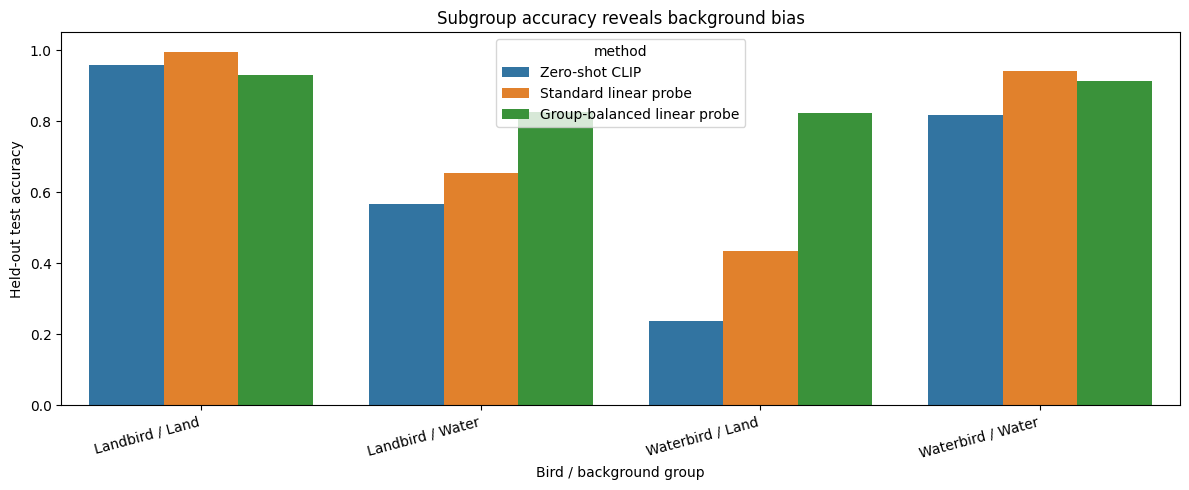

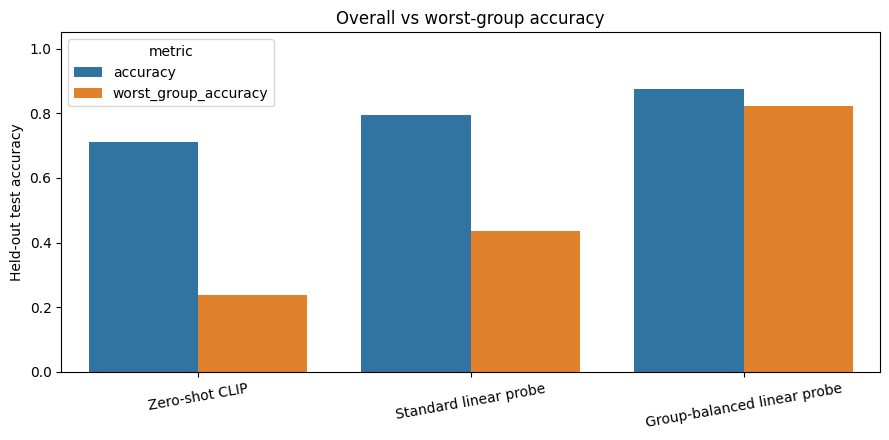

In [12]:
plot_rows = []
for name, data in all_metrics.items():
    for group, acc in data['by_group'].items():
        # Include denominator and number correct, so every bar is auditable.
        group_index = [g for g, group_name in GROUP_NAMES.items() if group_name == group][0]
        sample_mask = (2*y_test + p_test == group_index)
        n = int(sample_mask.sum())
        correct_n = int((predictions[name][sample_mask] == y_test[sample_mask]).sum())
        plot_rows.append({'method': name, 'group': group,
                          'correct': correct_n, 'n': n, 'accuracy': acc})
group_df = pd.DataFrame(plot_rows)
group_df.to_csv(OUT / 'test_group_accuracies.csv', index=False)
plt.figure(figsize=(12, 5))
sns.barplot(data=group_df, x='group', y='accuracy', hue='method')
plt.ylim(0, 1.05); plt.ylabel('Held-out test accuracy'); plt.xlabel('Bird / background group')
plt.xticks(rotation=15, ha='right'); plt.title('Subgroup accuracy reveals background bias')
plt.tight_layout(); plt.savefig(OUT / 'fig_03_group_accuracy.png', dpi=180); plt.show()

plot_summary = summary.melt(id_vars='method', value_vars=['accuracy', 'worst_group_accuracy'],
                            var_name='metric', value_name='score')
plt.figure(figsize=(9, 4.5))
sns.barplot(data=plot_summary, x='method', y='score', hue='metric')
plt.ylim(0, 1.05); plt.ylabel('Held-out test accuracy'); plt.xlabel('')
plt.xticks(rotation=10); plt.title('Overall vs worst-group accuracy')
plt.tight_layout(); plt.savefig(OUT / 'fig_04_accuracy_comparison.png', dpi=180); plt.show()

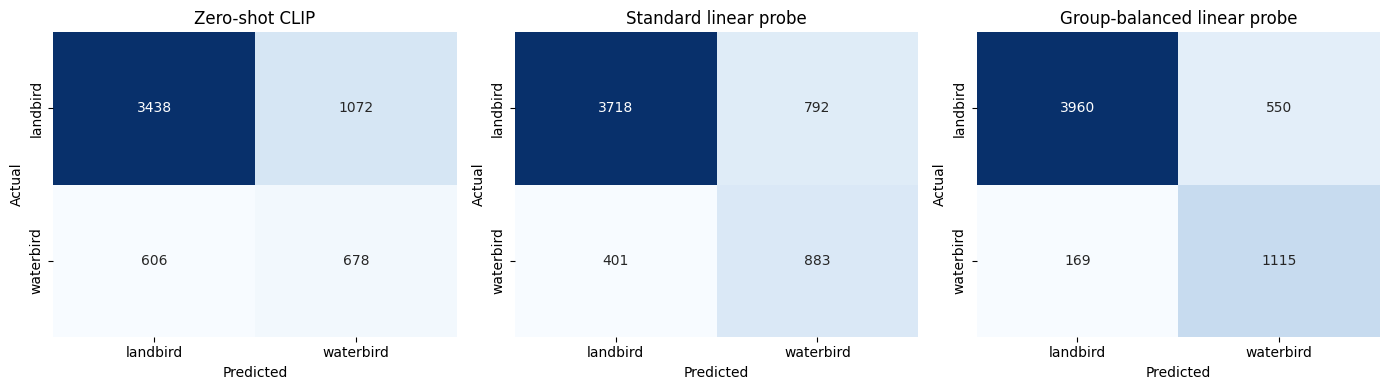

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['landbird','waterbird'], yticklabels=['landbird','waterbird'])
    ax.set_title(name); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout(); plt.savefig(OUT / 'fig_05_confusion_matrices.png', dpi=180); plt.show()

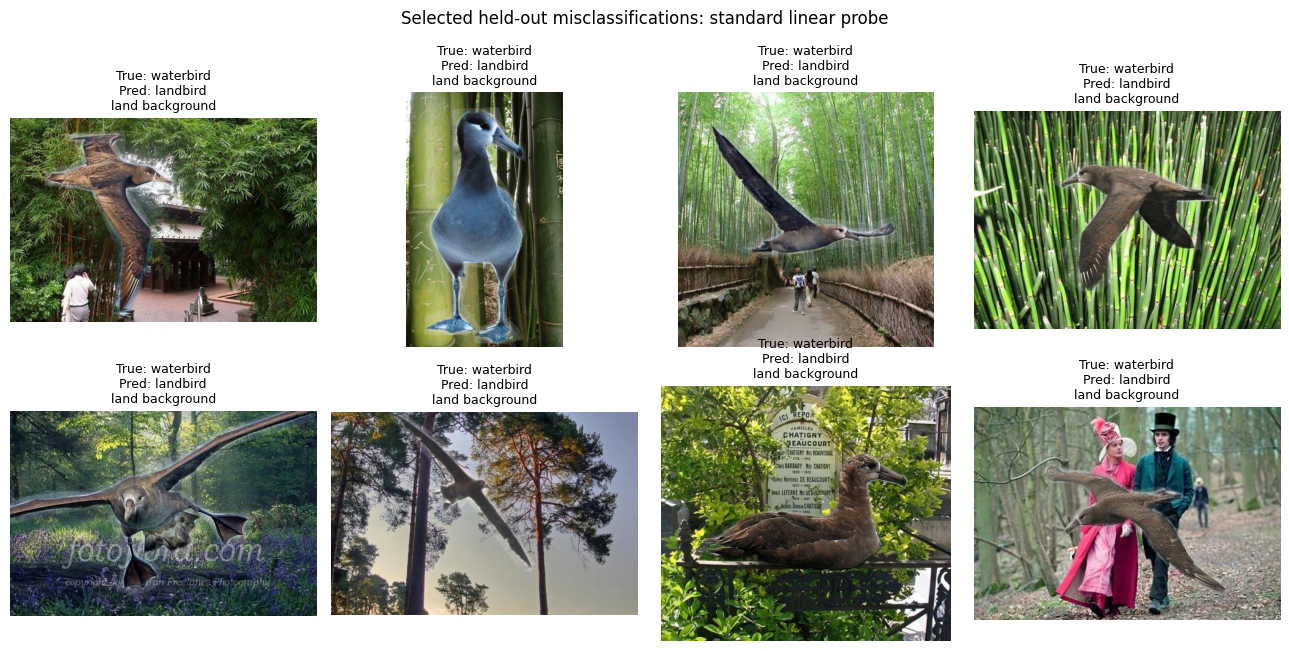

In [14]:
# Illustrative mistakes by the standard probe, prioritized to mismatched backgrounds.
standard_pred = predictions['Standard linear probe']
misaligned = (y_test != p_test)
wrong = (standard_pred != y_test)
chosen = np.flatnonzero(misaligned & wrong)[:8]
if len(chosen) == 0:
    chosen = np.flatnonzero(wrong)[:8]
if len(chosen) == 0:
    print('No errors found for this model; no error examples to display.')
else:
    ncols = 4
    nrows = int(np.ceil(len(chosen) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(13, nrows*3.3), squeeze=False)
    for ax in axes.ravel(): ax.axis('off')
    for ax, idx in zip(axes.ravel(), chosen):
        ax.imshow(ds['test'][int(idx)]['image'].convert('RGB'))
        ax.set_title(f'True: {CLASS_NAMES[int(y_test[idx])]}\nPred: {CLASS_NAMES[int(standard_pred[idx])]}\n{PLACE_NAMES[int(p_test[idx])]}', fontsize=9)
        ax.axis('off')
    plt.suptitle('Selected held-out misclassifications: standard linear probe')
    plt.tight_layout(); plt.savefig(OUT / 'fig_06_error_examples.png', dpi=180); plt.show()

## 8 · Export reproducibility details

Use the CSV and PNG files in the technical report. Keep the notebook with all executed outputs (save a copy after running). Outputs are stored under `maai901_outputs/` and can be zipped/downloaded from Colab. Avoid uploading the entire Waterbirds dataset to GitHub; upload code, figures and non-sensitive summary metrics.

In [15]:
record = {
    'seed': SEED, 'clip_backbone': 'ViT-B/32', 'frozen_encoder': True,
    'dataset': 'grodino/waterbirds', 'dataset_counts': expected,
    'classes': CLASS_NAMES, 'backgrounds': PLACE_NAMES, 'prompts': PROMPTS,
    'C_options': C_OPTIONS,
    'standard_C': float(trials_standard.sort_values(['val_worst_group','val_accuracy','C'], ascending=[False,False,True]).iloc[0]['C']),
    'balanced_C': float(trials_balanced.sort_values(['val_worst_group','val_accuracy','C'], ascending=[False,False,True]).iloc[0]['C']),
    'model_selection': 'Validation worst-group accuracy, then overall accuracy, then lower C',
    'device': DEVICE, 'bootstrap_resamples': N_BOOTSTRAPS, 'torch_version': torch.__version__,
    'sklearn_version': sklearn.__version__, 'python_version': sys.version.split()[0]
}
with open(OUT / 'experiment_config.json', 'w') as f: json.dump(record, f, indent=2)
# Short plain-text export to simplify transfer to the report.
with open(OUT / 'READ_ME_FIRST_results.txt', 'w', encoding='utf8') as f:
    f.write('MAAI901 Waterbirds + CLIP — observed results (not predictions)\n')
    f.write('All numbers below describe the official held-out test split.\n\n')
    f.write(summary.to_string(index=False, float_format=lambda v: f'{v:.4f}'))
    f.write('\n\nBalanced minus standard worst-group accuracy: '
            f'{point_diff:+.4f} (95% paired bootstrap [{diff_low:+.4f}, {diff_high:+.4f}])\n')
print('The file READ_ME_FIRST_results.txt contains the key results for the report.')

import shutil
archive_path = shutil.make_archive('MAAI901_CLIP_Waterbirds_results', 'zip', root_dir=str(OUT))
print('Saved result archive:', archive_path)
try:
    from google.colab import files
    print('In Colab, uncomment the next line if you want to download:')
    print(' # files.download(archive_path)')
except ImportError:
    print('Result files are in:', OUT.resolve())


print('The summary text file is included in the results ZIP.')


The file READ_ME_FIRST_results.txt contains the key results for the report.
Saved result archive: /content/MAAI901_CLIP_Waterbirds_results.zip
In Colab, uncomment the next line if you want to download:
 # files.download(archive_path)
The summary text file is included in the results ZIP.


## 9 · Writing prompts for the report (fill ONLY from observed results)

1. **Dataset:** Why do training and test distributions differ? Compare group counts. How might synthetic compositing affect generalization?
2. **Model/implementation:** Why is frozen CLIP an appropriate advanced model? What are its 224-pixel preprocessing and prompt-design limitations? Explain embeddings and the weighted logistic objective.
3. **Evaluation:** Report accuracy, macro F1, worst-group accuracy and alignment gap for all three methods. Describe which class–background group is hardest and inspect error examples.
4. **Ethics:** Avoid claiming this bird benchmark *measures demographic fairness*. It primarily evaluates robustness to a spurious contextual feature. Discuss how similar background shortcuts could lead to unequal performance in real-world vision systems, including ecological monitoring.
5. **Limitations:** No end-to-end fine-tuning; performance depends on pretrained CLIP representations; group labels required for mitigation; one dataset and one seed; synthetic backgrounds; prompt choice; and potentially correlated species/scene patterns.
6. **Conclusion:** Accept or reject the hypothesis based on the *held-out* worst-group result; acknowledge any overall accuracy trade-off.

Suggested references: Radford et al. (2021); Sagawa et al. (2020); Kirichenko et al. (2023).